# 현실의 데이터 17: 자율주행: 옆 차 궤적 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/17_vehicle_trajectory.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 자율주행 · 예측 (prediction) · 궤적 데이터 · 시공간

> 고속도로 차들의 0.1초 간격 위치. 옆 차는 3초 뒤 어디에 있을까?

**데이터**: NGSIM US-101 Vehicle Trajectories (약 45MB). 미국 교통부 NGSIM: 로스앤젤레스 US-101 고속도로 약 640m 구간을 건물 위 카메라로 찍어 차량마다 0.1초 간격으로 위치 · 속도 · 차선을 기록한 공개 데이터. 여기서는 차량 번호 600 미만의 60만 줄만 받는다.

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 차 한 대의 한 순간 (지난 2초를 보고) |
| ② 입력 X | 지난 2초 동안의 위치 (0.5초 간격 5개, 지금 위치 기준) |
| ③ 출력 y | 앞으로 3초의 위치 (0.5초 간격 6개, x · y) |
| ④ 평가지표 | ADE · FDE (미터) |
| ⑤ 기준선 | 지금 속도 그대로 직진 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Deo & Trivedi (2018) Convolutional Social Pooling for Vehicle Trajectory Prediction, CVPRW (NGSIM US-101 · I-80)](https://doi.org/10.1109/CVPRW.2018.00196)
- [Ettinger et al. (2021) Large Scale Interactive Motion Forecasting for Autonomous Driving: The Waymo Open Motion Dataset, ICCV](https://arxiv.org/abs/2104.10133)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

미국 교통부 공개 API 에서 필요한 열만, 차량 · 시각 순서로 받는다 (약 45MB, 1~2분).

In [2]:
URL = ("https://data.transportation.gov/resource/8ect-6jqj.csv?$select=vehicle_id,frame_id,global_time,local_x,local_y,v_vel,v_acc,lane_id,v_class,v_length"
       "&$where=location%3D%27us-101%27%20AND%20vehicle_id%3C600&$order=vehicle_id,global_time&$limit=600000")
df = pd.read_csv(download(URL, "data/ngsim_us101_v.csv")).drop_duplicates(["vehicle_id", "global_time"])
FT = 0.3048                                    # feet -> meters
df["x"], df["y"] = df["local_x"] * FT, df["local_y"] * FT        # x = across lanes, y = along the road
print(df.shape)
df.sample(5, random_state=0)

(584819, 12)


,vehicle_id,frame_id,global_time,local_x,local_y,v_vel,v_acc,lane_id,v_class,v_length,x,y
471241,299,1398,1118848896800,5.906,380.907,24.42,-1.25,1,2,17.5,1.800149,116.100454
59371,39,423,1118847884300,27.360,84.261,15.00,0.00,3,2,15.5,8.339328,25.682753
217187,138,1256,1118848882600,41.442,1793.162,10.10,-2.06,4,2,16.0,12.631522,546.555778
533747,335,2349,1118848991900,52.099,1773.764,43.81,2.65,5,2,15.5,15.879775,540.643267
222833,141,1182,1118848875200,30.873,1462.467,22.59,11.20,3,2,15.5,9.410090,445.759942


## 열어 보기: 같은 번호, 다른 차?

같은 `vehicle_id` 가 다른 시간대에 다시 나온다 (촬영 구간마다 번호를 새로 매겼다). 시간이 0.1초보다 크게 끊기면 다른 궤적으로 나눈다 (1주 3차시 '같다의 기준은 사람이 정한다').

trajectories: 939 | seconds per trajectory: median 57.0


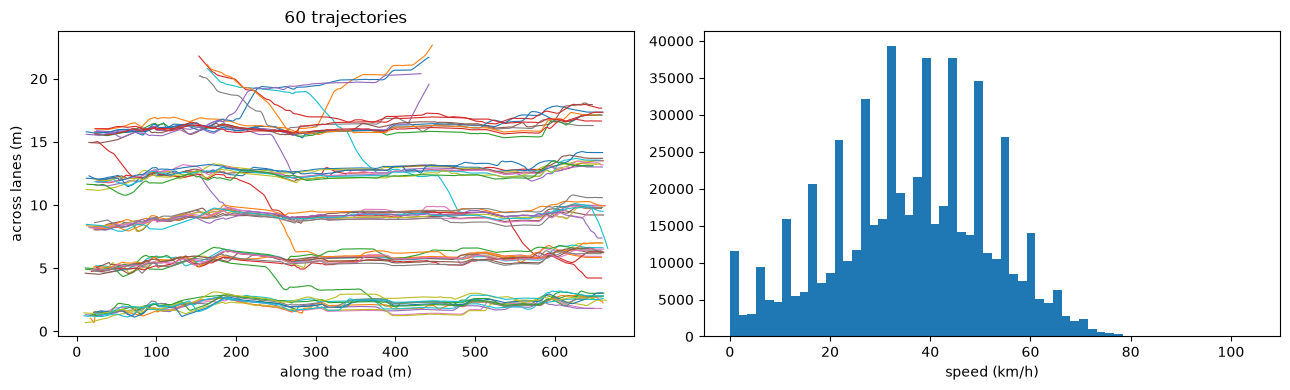

In [3]:
df = df.sort_values(["vehicle_id", "global_time"])
df["track"] = (df.groupby("vehicle_id")["global_time"].diff() != 100).cumsum()
lengths = df.groupby("track").size() / 10
print("trajectories:", df["track"].nunique(), "| seconds per trajectory: median", lengths.median())
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for tid in df["track"].unique()[:60]:
    g = df[df["track"] == tid]; axs[0].plot(g["y"], g["x"], lw=0.8)
axs[0].set_xlabel("along the road (m)"); axs[0].set_ylabel("across lanes (m)"); axs[0].set_title("60 trajectories")
axs[1].hist(df["v_vel"] * FT * 3.6, bins=60); axs[1].set_xlabel("speed (km/h)")
plt.tight_layout(); plt.show()

## 문제로 만들기: 지난 2초 → 앞으로 3초

궤적마다 1초 간격으로 순간을 잡고, **지금 위치를 원점으로** 지난 2초의 위치 5개 (0.5초 간격) 와 앞으로 3초의 위치 6개를 뽑는다 (1주 3차시: 창마다 기준 맞추기).

In [4]:
def make_windows(df):
    """Past 2 s (every 0.5 s) and future 3 s (every 0.5 s) positions, relative to the current position"""
    rows = []
    for tid, g in df.groupby("track"):
        if len(g) < 60:
            continue
        x, y, lane = g["x"].values, g["y"].values, g["lane_id"].values
        for s in range(20, len(g) - 30, 10):
            px, py, fx, fy = x[s - 20:s + 1:5], y[s - 20:s + 1:5], x[s + 5:s + 31:5], y[s + 5:s + 31:5]
            rows.append(dict(track=tid, **{f"px{k}": px[k] - px[-1] for k in range(4)}, **{f"py{k}": py[k] - py[-1] for k in range(4)},
                             **{f"fx{k}": fx[k] - px[-1] for k in range(6)}, **{f"fy{k}": fy[k] - py[-1] for k in range(6)},
                             lane_change=int(lane[s + 30] != lane[s])))
    return pd.DataFrame(rows)

W = make_windows(df)
print(W.shape, f"windows with a lane change in the next 3 s: {W['lane_change'].mean():.1%}")

(54205, 22) windows with a lane change in the next 3 s: 1.9%


## 기준선과 모델

**궤적 단위** 로 나눈다 (같은 차의 이웃한 순간이 학습 · 시험 양쪽에 있으면 쉬워진다). 지표:
- ADE = 6개 미래 위치의 평균 거리 오차, FDE = 3초 뒤 마지막 위치의 거리 오차 (미터)
- 기준선 1: 가만히 있다, 기준선 2: 지난 0.5초 속도 그대로

In [5]:
from sklearn.linear_model import Ridge

def ade_fde(pred_x, pred_y, W):
    d = np.hypot(pred_x - W[[f"fx{k}" for k in range(6)]].values, pred_y - W[[f"fy{k}" for k in range(6)]].values)
    return d.mean(), d[:, -1].mean()

rng = np.random.default_rng(0); tracks = W["track"].unique()
test_tracks = set(rng.choice(tracks, len(tracks) // 4, replace=False))
tr, te = W[~W["track"].isin(test_tracks)], W[W["track"].isin(test_tracks)]
steps = np.arange(1, 7)
cv_x, cv_y = np.outer(-te["px3"].values, steps), np.outer(-te["py3"].values, steps)      # last 0.5 s displacement, repeated
past = [f"px{k}" for k in range(4)] + [f"py{k}" for k in range(4)]
future = [f"fx{k}" for k in range(6)] + [f"fy{k}" for k in range(6)]
lin = Ridge(1.0).fit(tr[past], tr[future]).predict(te[past])
for name, (a, b) in [("stand still", (np.zeros((len(te), 6)), np.zeros((len(te), 6)))), ("constant velocity", (cv_x, cv_y)), ("linear model", (lin[:, :6], lin[:, 6:]))]:
    ade, fde = ade_fde(a, b, te)
    print(f"{name:18s} ADE {ade:.2f} m   FDE {fde:.2f} m")
lc = te["lane_change"].values == 1
print(f"only lane-change windows: constant velocity FDE {ade_fde(cv_x[lc], cv_y[lc], te[lc])[1]:.2f} m, linear FDE {ade_fde(lin[lc, :6], lin[lc, 6:], te[lc])[1]:.2f} m")

stand still        ADE 17.31 m   FDE 29.76 m
constant velocity  ADE 1.28 m   FDE 2.62 m
linear model       ADE 1.21 m   FDE 2.45 m
only lane-change windows: constant velocity FDE 3.50 m, linear FDE 3.38 m


**관찰**: '지금 속도 그대로' 가 아주 강한 기준선이다. 고속도로 차는 대부분 그대로 달리기 때문이다. 어려운 건 **차선 변경 · 끼어들기** 처럼 드문 순간이고, 자율주행에서 정말 중요한 것도 그 순간이다. 실제 예측 모델은 주변 차 · 차선 지도까지 입력에 넣는다 (아래 논문).

## 다른 문제로 바꿔 보기

- **차선 변경 예측 (분류)**: 출력을 '3초 안에 차선을 바꿀까' 로 바꾸면? 양성은 2% 정도라 정확도는 함정이다.
- **여러 미래**: 같은 순간에도 직진 · 차선 변경 두 미래가 가능하다. 예측을 하나가 아니라 여러 개 (확률과 함께) 내면 지표는? (Waymo Open Motion 의 minADE)
- **장면 인식**: 카메라 · LiDAR 로 주변 차를 찾는 단계는 포인트 클라우드 노트북과 이어진다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |